# Generate missing data in time series

## Goal

Hide values in time series (values become NaN while the time index stays intact), with an optional sktime bridge.

In [1]:
import badgers
badgers.__version__

'0.0.15'

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from badgers.generators.time_series.missingness import MissingAtRandomGenerator

## Setup random generator

In [3]:
from numpy.random import default_rng
seed = 0
rng = default_rng(seed)

## Import data (using sktime)

if sktime is not installed:

```bash
pip install sktime
```

In [4]:
from sktime.datasets import load_airline

In [5]:
X = load_airline()
t = X.index.to_timestamp()

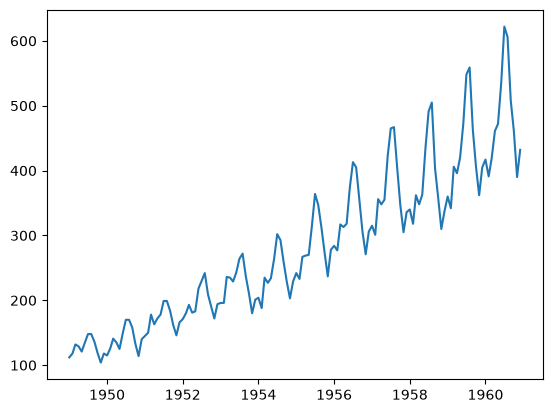

In [6]:
plt.plot(t, X.values)

## Missing randomly completely at random (1 Dimension)

In [7]:
gen = MissingAtRandomGenerator(random_generator=rng)

In [8]:
Xt = gen.generate(X.copy(), n_missing=10)

In [9]:
# verify: exactly n_missing values became NaN
print('NaN count:', int(np.isnan(Xt).sum()))
assert int(np.isnan(Xt).sum()) == 10


NaN count: 10


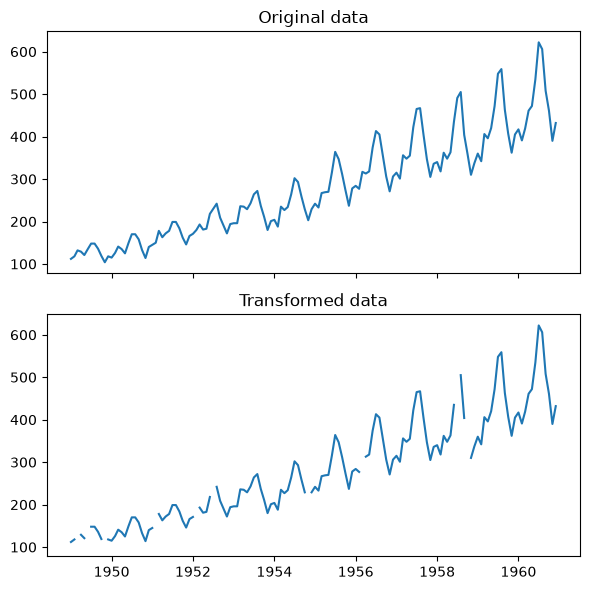

In [10]:
fig, axes = plt.subplots(2, sharex=True, sharey=True, figsize=(6,6))
axes[0].plot(t, X.values)
axes[0].set_title('Original data')
axes[1].plot(t, Xt)
axes[1].set_title('Transformed data')
plt.tight_layout();

## Missing randomly completely at random (2 Dimensions and more)

In [11]:
X = rng.normal(loc=(2,0), scale=(0.5, 0.1), size=(100,2))

In [12]:
Xt = gen.generate(X.copy(), n_missing=25)

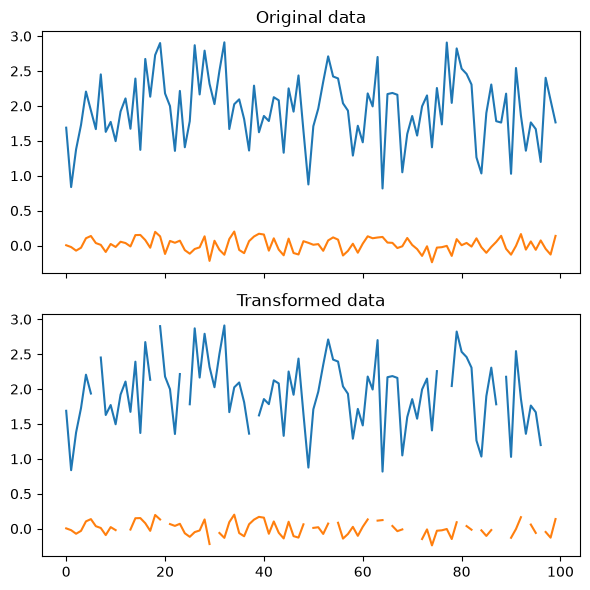

In [13]:
fig, axes = plt.subplots(2, sharex=True, sharey=True, figsize=(6,6))
axes[0].plot(X)
axes[0].set_title('Original data')
axes[1].plot(Xt)
axes[1].set_title('Transformed data')
plt.tight_layout();

## Takeaways

- Values become NaN; the time index is not affected (no rows removed).
- The causal variant chooses which positions hide values.